# Chapitre 1 - Cours 3 : cloud ou auto-hébergement

Deuxième grand compromis du chapitre : faut-il faire tourner soi-même ses systèmes de
données, ou les louer à un fournisseur de cloud ? La question est d'abord économique et
organisationnelle, mais le cloud a aussi transformé la **manière de construire** les
systèmes de données : stockage objet, séparation du stockage et du calcul,
multi-location. Ce notebook couvre la section *Cloud Versus Self-Hosting* : *Pros and
Cons of Cloud Services*, *Cloud Native System Architecture* (*Layering of cloud
services*, *Separation of storage and compute*) et *Operations in the Cloud Era*.

**Plan.**

1. Construire ou acheter, opérer ou externaliser : le spectre des choix.
2. Le coût : un modèle de coût total selon la taille et la variabilité de la charge.
3. Le contrôle : ce que l'on cède au fournisseur, et le prix de la sortie.
4. L'architecture cloud native : empilement des services et ordres de grandeur des
   couches de stockage.
5. Séparer stockage et calcul : disques éphémères, disques virtuels, caches.
6. La multi-location : mutualisation et voisins bruyants.
7. L'exploitation à l'ère du cloud : de la planification de capacité à la planification
   financière.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Construire ou acheter, opérer ou externaliser (section *Cloud Versus Self-Hosting*)

Pour toute activité, une organisation se demande si elle la fait elle-même ou si elle
l'achète. Règle empirique citée par le livre : ce qui relève du **cœur de métier** ou d'un
**avantage concurrentiel** se fait en interne ; ce qui est banal, routinier, se confie à
un fournisseur (presque personne ne fabrique ses propres processeurs). Pour le logiciel,
deux décisions se superposent : **qui écrit** le logiciel, et **qui le déploie et
l'exploite**.

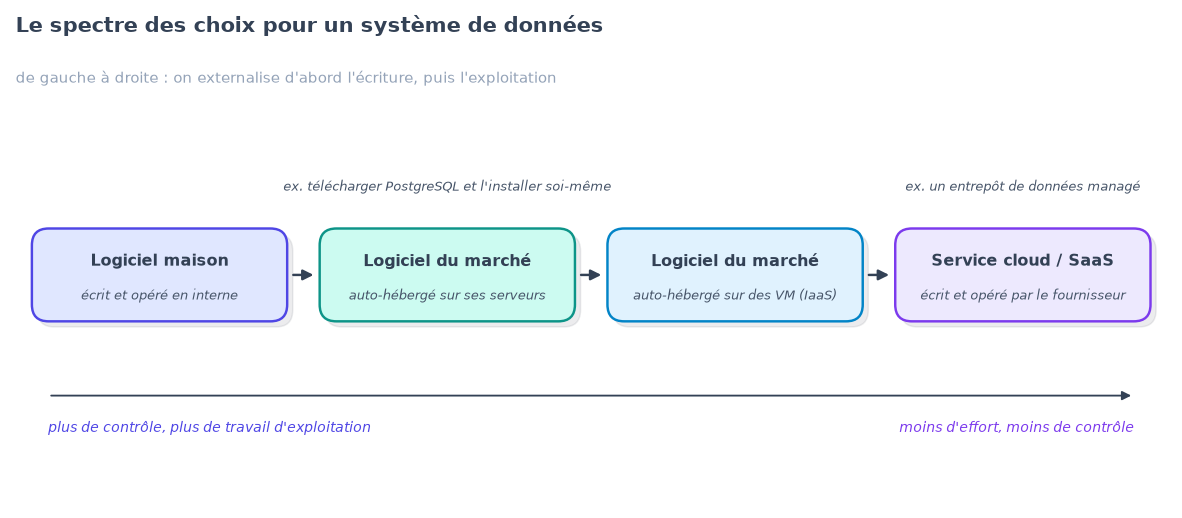

In [2]:
d = Diagram(12.5, 4.4, title="Le spectre des choix pour un système de données",
            subtitle="de gauche à droite : on externalise d'abord l'écriture, puis l'exploitation")
specs = [("custom", "Logiciel maison", "écrit et opéré en interne", INDIGO),
         ("onprem", "Logiciel du marché", "auto-hébergé sur ses serveurs", TEAL),
         ("iaas", "Logiciel du marché", "auto-hébergé sur des VM (IaaS)", SKY),
         ("saas", "Service cloud / SaaS", "écrit et opéré par le fournisseur", VIOLET)]
for i, (k, t, sub, c) in enumerate(specs):
    d.box(k, 1.6 + i * 3.1, 2.5, t, sub=sub, color=c, w=2.75, h=1.0)
for a, b in zip(specs, specs[1:]):
    d.arrow(a[0], b[0])
d.line([(0.4, 1.2), (12.1, 1.2)], color=SLATE, style="solid")
d.note(0.4, 0.85, "plus de contrôle, plus de travail d'exploitation", ha="left", color=INDIGO)
d.note(12.1, 0.85, "moins d'effort, moins de contrôle", ha="right", color=VIOLET)
d.note(4.7, 3.45, "ex. télécharger PostgreSQL et l'installer soi-même", fontsize=8.5)
d.note(10.9, 3.45, "ex. un entrepôt de données managé", fontsize=8.5)
d.show()

Au milieu du spectre, on trouve le logiciel du marché (libre ou commercial) qu'on
**auto-héberge** : sur son propre matériel (« on premises », même si le serveur est dans
une baie louée), ou sur une machine virtuelle louée à un cloud (*infrastructure as a
service*, IaaS). Il existe des points intermédiaires (un logiciel libre modifié, par
exemple). Le choix de l'outillage de déploiement (orchestrateur comme Kubernetes) est
laissé de côté par le livre : il pèse moins sur l'architecture des données.

> **À retenir.** Deux questions distinctes : qui écrit le logiciel, et qui l'exploite.
> On garde en interne ce qui fait la différence, on achète le reste.

## 2. Le coût : prévisible ou variable (section *Pros and Cons of Cloud Services*)

Les fournisseurs promettent économies et rapidité. Le livre nuance : si l'on sait **déjà**
exploiter le système, et si la charge est **prévisible** (le nombre de machines nécessaires
varie peu), acheter ses machines est souvent moins cher. À l'inverse, apprendre à exploiter
un système qu'on ne connaît pas, recruter et former une équipe, coûte cher ; et quand la
charge **varie beaucoup**, une flotte dimensionnée pour le pic reste inactive la plupart
du temps, alors qu'un cloud permet de rendre les ressources inutilisées.

**Un modèle de coût total.** On compare trois options pour servir une charge horaire
(fonction `ar.load_profile` : cycle quotidien de moyenne et de pic choisis) :

- **auto-hébergé** : serveurs achetés, dimensionnés pour le pic avec 30 % de marge,
  amortis à 250 € par mois et par serveur (achat, hébergement, électricité), plus
  10 000 € par mois d'exploitation (une part d'équipe) ;
- **cloud, flotte fixe** : même dimensionnement, mais en instances à 1,00 € l'heure
  (730 € par mois : près de trois fois le coût d'un serveur possédé), et seulement 3 000 € par mois
  d'exploitation ;
- **cloud, élastique** : on paie chaque heure le nombre d'instances nécessaire.

Les chiffres sont des ordres de grandeur plausibles, pas des tarifs : ce qui compte, ce
sont les **formes** des courbes. Un serveur traite 1 000 requêtes par seconde.

taux d'utilisation de la flotte fixe : 18%


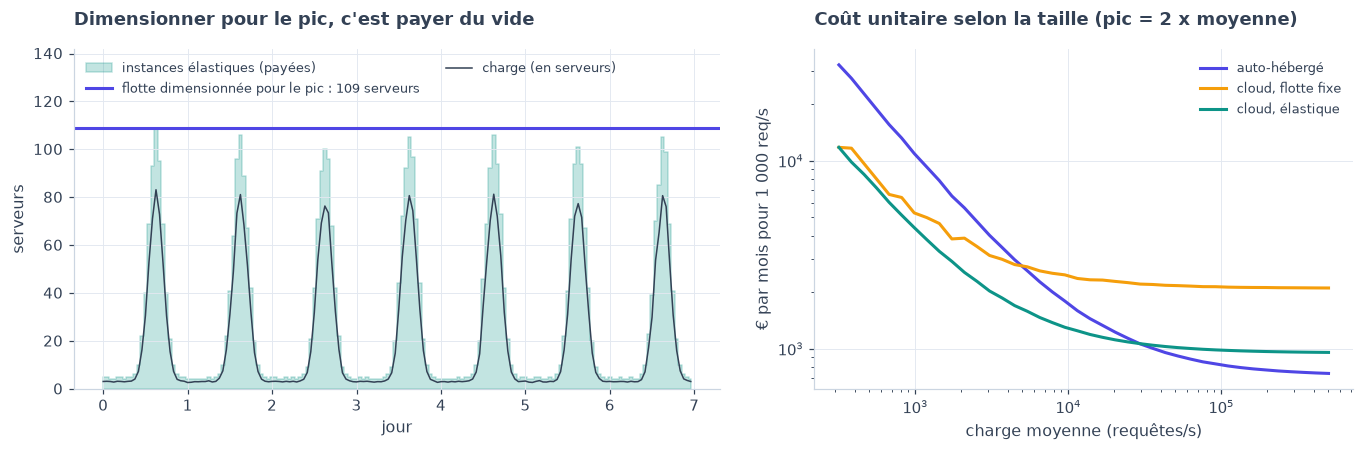

In [3]:
CAP, SRV_M, OPS_SELF, INST_H, OPS_CLOUD = 1000.0, 250.0, 10_000.0, 1.0, 3_000.0


def three_costs(mean, peak_ratio, seed=0):
    load = ar.load_profile(24 * 28, mean=mean, peak_ratio=peak_ratio, seed=seed)
    return (ar.cost_self_hosted(load, CAP, SRV_M, OPS_SELF),
            ar.cost_cloud(load, CAP, INST_H, OPS_CLOUD, autoscale=False),
            ar.cost_cloud(load, CAP, INST_H, OPS_CLOUD, autoscale=True))


load = ar.load_profile(24 * 7, mean=20_000, peak_ratio=4, seed=1)
n_auto = ar.servers_needed(load, CAP, 0.3)
n_peak = ar.servers_needed(load.max(), CAP, 0.3).item()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
h = np.arange(load.size) / 24
ax.fill_between(h, n_auto, step="mid", color=TEAL, alpha=0.25, label="instances élastiques (payées)")
ax.axhline(n_peak, color=INDIGO, lw=2, label=f"flotte dimensionnée pour le pic : {n_peak} serveurs")
ax.plot(h, load / CAP, color=SLATE, lw=1, label="charge (en serveurs)")
ax.set_xlabel("jour"); ax.set_ylabel("serveurs"); ax.set_ylim(0, n_peak * 1.3)
ax.set_title("Dimensionner pour le pic, c'est payer du vide")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
print(f"taux d'utilisation de la flotte fixe : {load.mean() / (n_peak * CAP):.0%}")

means = np.logspace(2.5, 5.7, 40)
costs = np.array([three_costs(m, 2) for m in means])
ax = axes[1]
for j, (lab, c) in enumerate([("auto-hébergé", INDIGO), ("cloud, flotte fixe", AMBER), ("cloud, élastique", TEAL)]):
    ax.loglog(means, costs[:, j] / (means / 1000), color=c, label=lab)
ax.set_xlabel("charge moyenne (requêtes/s)"); ax.set_ylabel("€ par mois pour 1 000 req/s")
ax.set_title("Coût unitaire selon la taille (pic = 2 x moyenne)")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

À gauche, la flotte fixe n'est utilisée qu'à moins de 20 % en moyenne : l'élasticité du cloud
récupère cette marge. À droite, le coût par unité de charge raconte l'histoire du livre.
À **petite échelle**, le coût fixe d'exploitation domine : le cloud (moins de travail
d'exploitation) l'emporte nettement. À **grande échelle**, le prix par machine domine : le
cloud en flotte fixe devient l'option la plus chère, et l'auto-hébergement finit par
passer sous le cloud élastique (vers quelques dizaines de milliers de requêtes par seconde
pour ce rapport pic/moyenne de 2). Où se situe le point de bascule ? Il dépend surtout de la
**variabilité** de la charge : balayons la charge moyenne et le rapport pic/moyenne.

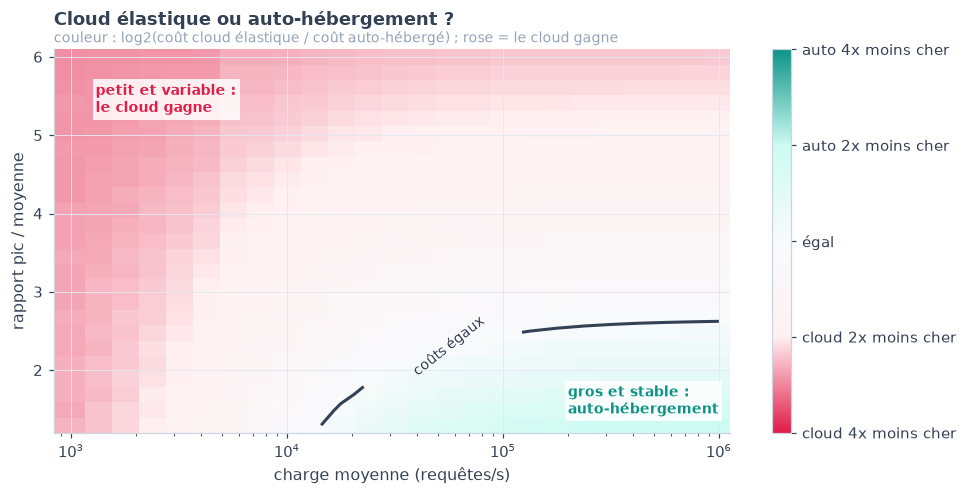

In [4]:
peaks = np.linspace(1.3, 6, 25)
means2 = np.logspace(3, 6, 25)
ratio = np.array([[three_costs(m, p)[2] / three_costs(m, p)[0] for m in means2] for p in peaks])
fig, ax = plt.subplots(figsize=(9, 4.6))
im = ax.pcolormesh(means2, peaks, np.log2(ratio), cmap="ddia_div", vmin=-2, vmax=2, shading="auto")
cs = ax.contour(means2, peaks, ratio, levels=[1.0], colors=[SLATE], linewidths=2)
ax.clabel(cs, fmt={1.0: "coûts égaux"}, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("charge moyenne (requêtes/s)"); ax.set_ylabel("rapport pic / moyenne")
cb = plt.colorbar(im, ax=ax); cb.set_ticks([-2, -1, 0, 1, 2])
cb.set_ticklabels(["cloud 4x moins cher", "cloud 2x moins cher", "égal", "auto 2x moins cher", "auto 4x moins cher"])
ax.set_title("Cloud élastique ou auto-hébergement ?")
subtitle(ax, "couleur : log2(coût cloud élastique / coût auto-hébergé) ; rose = le cloud gagne")
box = dict(fc="white", ec="none", alpha=0.85, pad=2)
ax.text(1.3e3, 5.3, "petit et variable :\nle cloud gagne", color=ROSE, fontsize=9, fontweight="bold", bbox=box)
ax.text(2e5, 1.45, "gros et stable :\nauto-hébergement", color=TEAL, fontsize=9, fontweight="bold", bbox=box)
plt.tight_layout(); plt.show()

La frontière confirme les deux critères du livre : une charge **petite** (l'exploitation
coûte cher relativement) ou **très variable** (la flotte fixe dort) favorise le cloud ;
une charge **grosse et stable** favorise l'auto-hébergement, à condition d'avoir les
compétences. Le cas typique de charge très variable est l'**analytique** : une requête
interactive sur un gros jeu de données veut beaucoup de machines pendant quelques
secondes, puis plus rien jusqu'à la suivante. Plus on la veut rapide, plus la charge
devient pointue : par exemple 200 machines pendant 30 secondes, dix fois par heure, soit
une utilisation moyenne de 8 % d'une flotte qui serait dimensionnée pour ces pointes.

Deux autres arguments jouent dans les deux sens : un fournisseur qui exploite le même
service pour des milliers de clients accumule une **expertise** qu'aucune équipe interne
n'égale ; mais il ne **personnalisera** pas son service pour votre charge particulière.

> **À retenir.** Le cloud gagne quand la charge est petite ou très variable (on rend
> ce qu'on n'utilise pas, on n'entretient pas d'équipe) ; l'auto-hébergement gagne quand
> elle est grosse, stable, et qu'on sait exploiter le système.